# Факультатив "Анализ данных"

## Практическое задание №1

Используйте данные из файла **StudentPerformanceFactors.csv** с информацией о студентах.

[Источник](https://www.kaggle.com/datasets/lainguyn123/student-performance-factors/code)

В нём содержаться следующие переменные:


| Название переменной | Описание переменной 
|:-------------------:|:------------------:|
| Hours_Studied | Number of hours spent studying per week |
| Attendance | Percentage of classes attended | 
| Parental_Involvement | Level of parental involvement in the student's education (Low, Medium, High)| 
| Access_to_Resources | Availability of educational resources (Low, Medium, High)| 
| Extracurricular_Activities | Participation in extracurricular activities (Yes, No).
| Sleep_Hours | Average number of hours of sleep per night.
| Previous_Scores |	Scores from previous exams.
| Motivation_Level |	Student's level of motivation (Low, Medium, High).
| Internet_Access |	Availability of internet access (Yes, No).
| Tutoring_Sessions |	Number of tutoring sessions attended per month.
| Family_Income |	Family income level (Low, Medium, High).
| Teacher_Quality |	Quality of the teachers (Low, Medium, High).
| School_Type |	Type of school attended (Public, Private).
| Peer_Influence |	Influence of peers on academic performance (Positive, Neutral, Negative).
| Physical_Activity |	Average number of hours of physical activity per week.
| Learning_Disabilities |	Presence of learning disabilities (Yes, No).
| Parental_Education_Level |	Highest education level of parents (High School, College, Postgraduate).
| Distance_from_Home |	Distance from home to school (Near, Moderate, Far).
| Gender |	Gender of the student (Male, Female).
| Exam_Score |	Final exam score.


In [1]:
# здесь можно написать код
%pip install pandas matplotlib seaborn scipy kagglehub

Note: you may need to restart the kernel to use updated packages.


In [57]:
import math

import kagglehub
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
import seaborn as sns

In [58]:
# Download dataset
file_path = kagglehub.dataset_download(
    "lainguyn123/student-performance-factors",
    path="StudentPerformanceFactors.csv",
    output_dir="data",
    force_download=True
)

df = pd.read_csv(file_path)

100%|██████████| 627k/627k [00:00<00:00, 914kB/s]


Выполните, пожалуйста, следующие задания.

1. Опишите датасет (число наблюдений и переменных, пропущенных значений, типы данных, типы шкал переменных).

<h3 style="color: green">1. Решение</h3>

In [59]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [60]:
var_types = {
    'Hours_Studied': 'абсолютная',
    'Attendance': 'абсолютная',
    'Parental_Involvement': 'ординальная',
    'Access_to_Resources': 'ординальная',
    'Extracurricular_Activities': 'бинарная',
    'Sleep_Hours': 'абсолютная',
    'Previous_Scores': 'интервальная',
    'Motivation_Level': 'ординальная',
    'Internet_Access': 'бинарная',
    'Tutoring_Sessions': 'абсолютная',
    'Family_Income': 'ординальная',
    'Teacher_Quality': 'ординальная',
    'School_Type': 'номинальная',
    'Peer_Influence': 'ординальная',
    'Physical_Activity': 'абсолютная',
    'Learning_Disabilities': 'бинарная',
    'Parental_Education_Level': 'ординальная',
    'Distance_from_Home': 'ординальная',
    'Gender': 'номинальная',
    'Exam_Score': 'интервальная'
}

ds_overview = pd.DataFrame({
    'Metric': ['Observations', 'Variables'],
    'Value': [len(df), len(df.columns)]
})

var_overview = pd.DataFrame({
    'Data type': df.dtypes,
    'Scale': pd.Series(var_types),
    'Missing': df.isna().sum()
})

print(ds_overview)
print(var_overview)

var_overview = pd.DataFrame({
    'Data type': df.dtypes,
    'Scale': pd.Series(var_types),
    'Missing': df.isna().sum()
})

         Metric  Value
0  Observations   6607
1     Variables     20
                           Data type         Scale  Missing
Hours_Studied                  int64    абсолютная        0
Attendance                     int64    абсолютная        0
Parental_Involvement             str   ординальная        0
Access_to_Resources              str   ординальная        0
Extracurricular_Activities       str      бинарная        0
Sleep_Hours                    int64    абсолютная        0
Previous_Scores                int64  интервальная        0
Motivation_Level                 str   ординальная        0
Internet_Access                  str      бинарная        0
Tutoring_Sessions              int64    абсолютная        0
Family_Income                    str   ординальная        0
Teacher_Quality                  str   ординальная       78
School_Type                      str   номинальная        0
Peer_Influence                   str   ординальная        0
Physical_Activity              

Заменим `NaN` в категориальных переменных:
- Teacher_Quality: `mode`
- Parental_Education_Level: `mode`
- Distance_from_Home: `mode`

In [61]:
df['Teacher_Quality'] = df['Teacher_Quality'].fillna(df['Teacher_Quality'].mode()[0])
df['Parental_Education_Level'] = df['Parental_Education_Level'].fillna(df['Parental_Education_Level'].mode()[0])
df['Distance_from_Home'] = df['Distance_from_Home'].fillna(df['Distance_from_Home'].mode()[0])

2. Проведите описательный анализ переменных датасета, используя подходящие методы анализа в зависимости от типа шкалы измерения переменной (частотный анализ данных, сводные таблицы, меры центральной тенденции и меры разброса, характеристики распределений переменных, графический анализ данных). Интерпретируйте полученные результаты. Обратите внимание, что анализ данных предполагает следующие этапы:
- постановка задачи и выбор переменных,
- обоснование выбора метода анализа,
- проведение расчётов,
- интерпретация результатов.

Например, я хотела бы проанализировать физическую активность студентов. Для этого я рассматриваю переменную "Physical_Activity". Поскольку она имеет метрическую шкалу измерения для ее анализа целесообразно построить гистограмму распределения значений и рассчитать описательные статистики. Далее делаете выводы на основе проведенных расчётов.

<h3 style="color: green">2. Решение</h3>

- постановка задачи и выбор переменных:

Определить, как уровень учебной мотивации связан с влиянием сверстников и типом школы

Переменные:
- - категориальная (ординальная) переменная `Motivation_Level`
- - категориальная (ординальная) переменная `Peer_Influence`
- - категориальная (номинальная) `School_Type`


- обоснование выбора метода анализа

В качестве основного метода будет использован частотный анализ, для визуализации будем использовать столбиковую диаграмму.
Использование категориальных переменных опредлеяет выбор метода анализа и визуализации, т.к. распределение ограничено всего несколькими значениями.

- проведение расчётов: 



Motivation_Level       High        Low     Medium
Peer_Influence                                   
Negative          20.769789  30.283224  48.946986
Neutral           19.290123  28.433642  52.276235
Positive          20.204701  29.681577  50.113723 

Motivation_Level       High        Low     Medium
School_Type                                      
Private           19.263315  30.064709  50.671976
Public            20.269682  28.990866  50.739452 



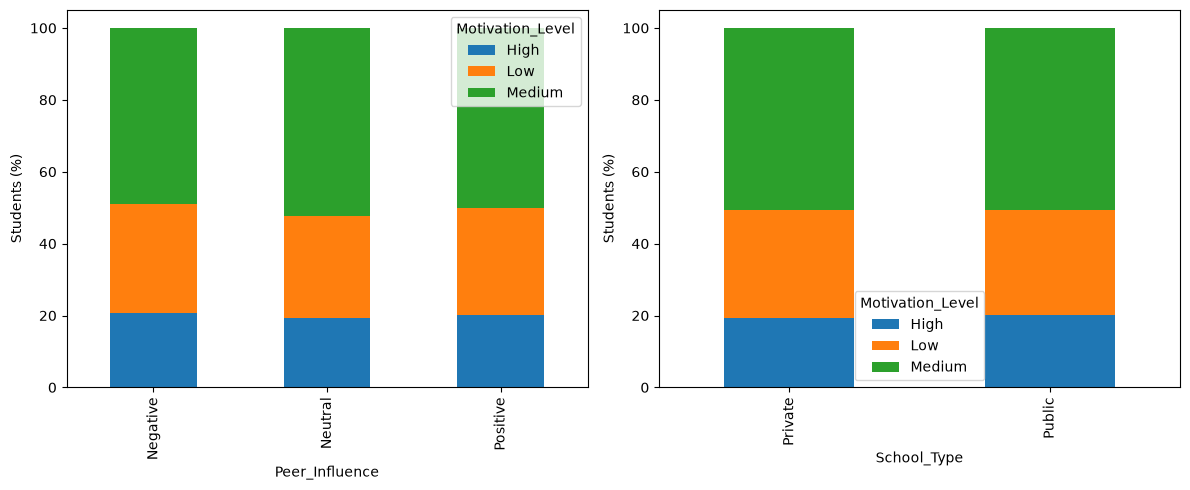

In [62]:
plt.figure(figsize=(12, 5))

for i, col in enumerate(['Peer_Influence', 'School_Type']):
    result = pd.crosstab(
        df[col],
        df['Motivation_Level'],
        normalize='index'
    ) * 100

    print(result, '\n')

    plt.subplot(1, 2, i + 1)
    result.plot(kind='bar', stacked=True, ax=plt.gca())
    plt.ylabel('Students (%)')

plt.tight_layout()
plt.show()

- интерпретация результатов:

*Уровень мотивации практически не отличается независимо от влияния сверстников или типа школы*

*При разделении студентов по типу влияния сверстников мотивация остается `Medium` у около 50%, `Low` около 30% и `High` около 20% студентов*

*То же распределение мотивации сохраняется при разделении студентов по типу оконченной школы. Преобладают студенты с мтоивацей `Medium` (около 50%), затем `Low` (около 30%), мотивация `High` наблюдается у меньшего количества студентов (около 20%)**

*Описательный анализ не выявил влияния переменных `Peer_Influence` и `School_Type` на переменную `Motivation_Level`*

3. Ответьте на вопросы (возможно, на некоторые из них Вы уже ответили в предыдущем пункте):
    - Какой процент студентов имеют высокую мотивированию?
    - Какого соотношение числа студентов с разным уровнем вовлеченности родителей в их обучение по группам уровня дохода семьи?
    - Наблюдается ли взаимосвязь между числом часов сна ночью и посещаемостью занятий?
    - Как различаются оценки юношей и девушек, живущих в разной удаленности от места обучения?
    - Какова специфика распределения финальных оценок за экзамен?
    - Наблюдается ли взаимосвязь между уровнем мотивации студентов и качеством преподавания?
    - Какими характеристиками обладают студенты-отличники (сами определите каких студентов отнести к отличникам)?
    - Какие факторы положительно взаимосвязаны с результатами экзамена (на этом этапе мы изучаем взаимосвязи на основе описательного анализа данных)?
    - Какие переменные имеют распределение, близкое к нормальному?
    - В распределении значений каких метрических переменных наблюдается асимметрия?
    

<h3 style="color: green">3. Решение</h3>

- Какой процент студентов имеют высокую мотивированию?

In [63]:
motivated_students = (df['Motivation_Level'] == 'High').mean() * 100
print(f'Процент студентов с высокой потивацей: {motivated_students}')


Процент студентов с высокой потивацей: 19.9636748902679


- Каково соотношение числа студентов с разным уровнем вовлеченности родителей в их обучение по группам уровня дохода семьи?

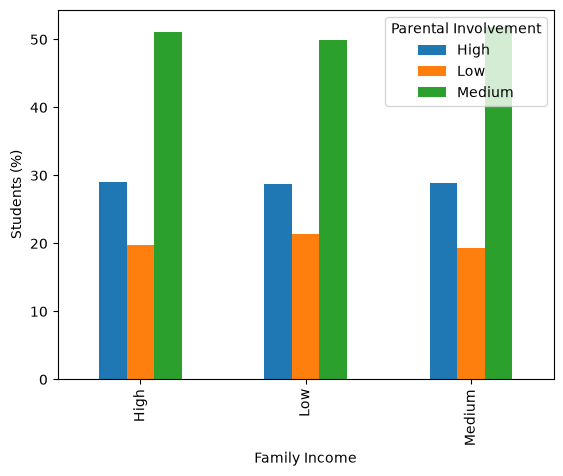

In [64]:
involvement_income = pd.crosstab(df['Family_Income'],
                                 df['Parental_Involvement'],
                                 normalize='index'
                                 ) * 100

involvement_income.plot(kind='bar')

plt.xlabel('Family Income')
plt.ylabel('Students (%)')
plt.legend(title='Parental Involvement')
plt.show()

<span style='color: green'>Вывод:</span>  *Не выявлено связи уровня вовлеченности родителей и уровне дохода. Распределение уровня вовлеченности практически одинаково во всех группах*

- Наблюдается ли взаимосвязь между числом часов сна ночью и посещаемостью занятий?

Есть ли смысл использовать корелляцию Пирсона?
 Нет 

 "Attendance": KstestResult(statistic=np.float64(0.07155244672648309), pvalue=np.float64(7.356698258106651e-30), statistic_location=np.float64(90.0), statistic_sign=np.int8(-1)) 
 "Sleep_Hours": KstestResult(statistic=np.float64(0.13187981576336105), pvalue=np.float64(1.1650978959116212e-100), statistic_location=np.float64(7.0), statistic_sign=np.int8(-1))
Коэффициент корреляции Спирмана: -0.01263561738979931


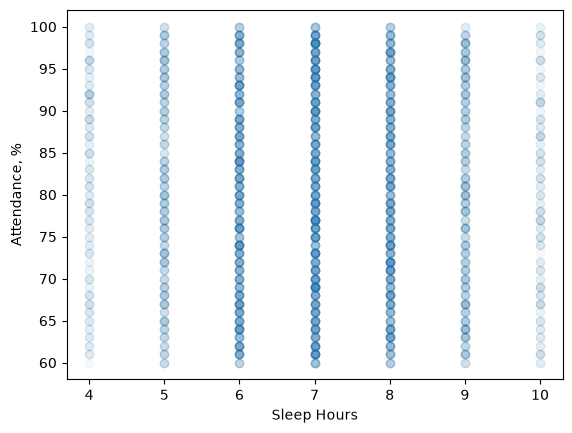

In [65]:
sleep_norm = stats.kstest(df['Sleep_Hours'], stats.norm.cdf, args=(df['Sleep_Hours'].mean(), df['Sleep_Hours'].std()))
attendance_norm = stats.kstest(df['Attendance'], stats.norm.cdf, args=(df['Attendance'].mean(), df['Attendance'].std()))
print('Есть ли смысл использовать корелляцию Пирсона?\n', 'Есть' if min(sleep_norm.pvalue, attendance_norm.pvalue) > 0.05 else 'Нет', '\n\n', f'"Attendance": {attendance_norm}', '\n', f'"Sleep_Hours": {sleep_norm}')

spearman_r = df['Sleep_Hours'].corr(df['Attendance'], method='spearman')
print(f'Коэффициент корреляции Спирмана: {spearman_r}')

plt.scatter(df['Sleep_Hours'], df['Attendance'], alpha=0.02)
plt.xlabel('Sleep Hours')
plt.ylabel('Attendance, %')
plt.show()


<span style='color: green'>Вывод:</span> 

*Несмотря на то что большинство студентов спит 6-8 hours - коэффициент корреляции низкий, диаграмма рассеивания не показывает линейной или монотонной зависимости. Можно сделать вывод, что связь `Sleep_Hours/Attendance` отсутствует*.

- Как различаются оценки юношей и девушек, живущих в разной удаленности от места обучения?


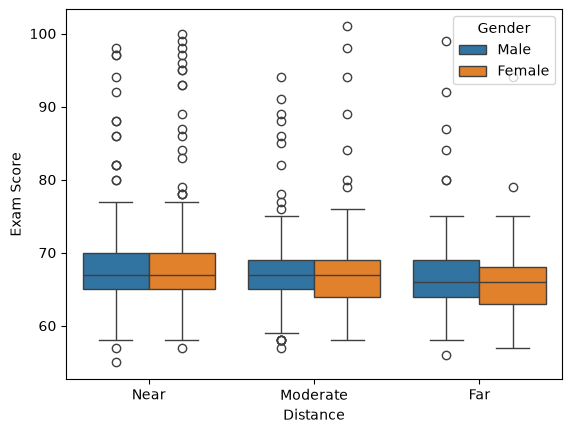

In [66]:
sns.boxplot(
    data=df,
    x='Distance_from_Home',
    y='Exam_Score',
    hue='Gender'
)
plt.xlabel('Distance')
plt.ylabel('Exam Score')
plt.show()

<span style='color: green'>Вывод:</span> 

*Удаленность от места учебы слабо связана с оценками: есть слабая связь с понижением медианы при значиетльной удаленности проживания.*

*Также оценки практически не отличаются в зависимости от пола: медиана не отличается у юношей и девушек.*

*Наблюдается некоторое отличие в экстремально высоких баллах: чем ближе - тем больше выборосов в сторону более высоких оценок*

- Какова специфика распределения финальных оценок за экзамен?


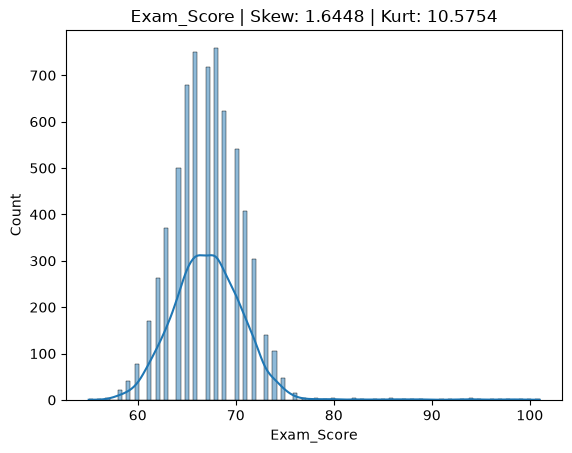

In [67]:
var = 'Exam_Score'
sns.histplot(df[var], kde=True)
plt.title(f'{var} | Skew: {round(df[var].skew(), 4)} | Kurt: {round(df[var].kurt(), 4)}')
plt.show()

<span style='color: green'>Вывод:</span> 

*Асимметрия правосторонняя (~1.64) свидетельствует разнообразии выбросов оценок выше медианных.*

*Эксцесс "заостренный" (~10.58) свидетельтсвует о том, что большая часть значений концентрируется вокруг медианы.*

- Наблюдается ли взаимосвязь между уровнем мотивации студентов и качеством преподавания?


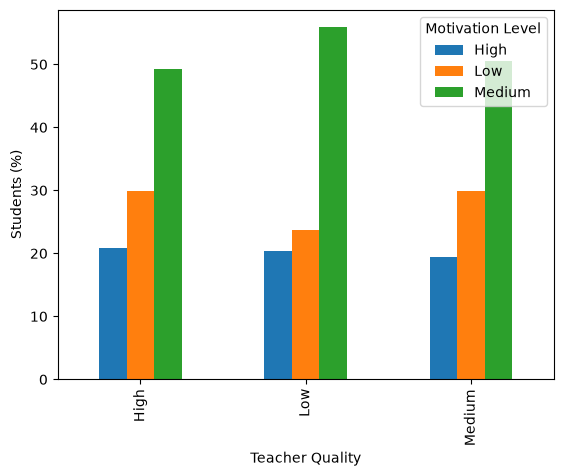

In [68]:
motivation_teacher = pd.crosstab(df['Teacher_Quality'],
                                 df['Motivation_Level'],
                                 normalize='index'
                                 ) * 100
motivation_teacher.plot(kind='bar')

plt.xlabel('Teacher Quality')
plt.ylabel('Students (%)')
plt.legend(title='Motivation Level')
plt.show()

<span style='color: green'>Вывод:</span> 

*Распределение мотивации схоже. Можно отметить некоторое влияние низкого качества преподавания на группы с уровнем мотивации `Low` (снижается) и `Medium` (возрастает).*

*Значимого влияния качества преподававния на мотивацию студентов не выявлено*

- Какими характеристиками обладают студенты-отличники (сами определите каких студентов отнести к отличникам)?


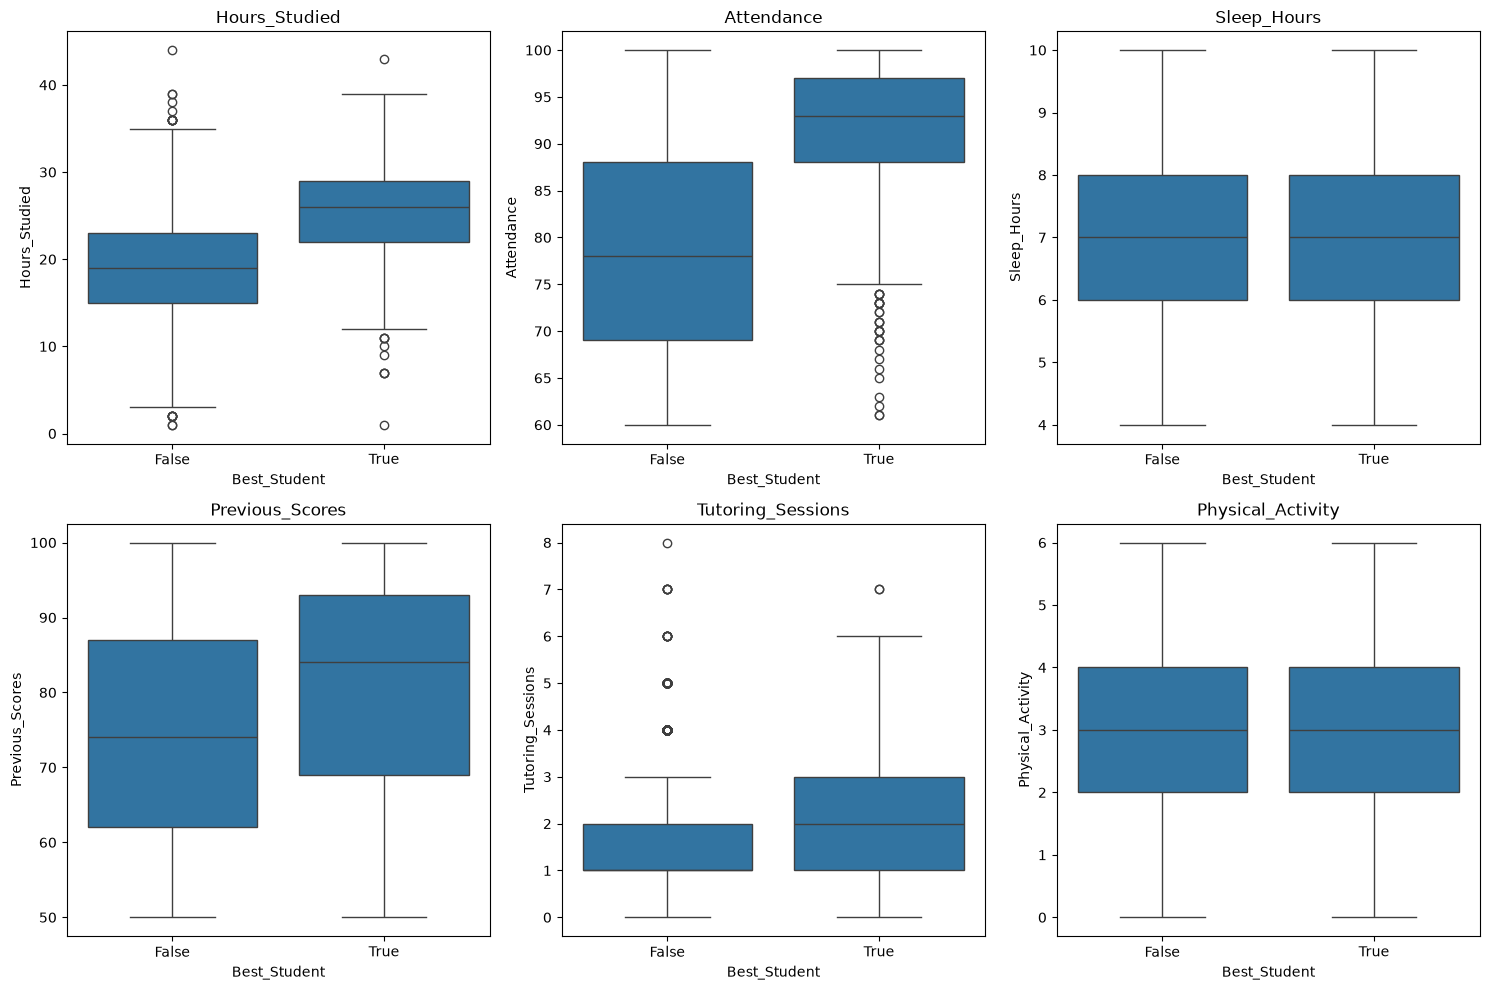

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity
Best_Student,,,,,,
False,19.0,78.0,7.0,74.0,1.0,3.0
True,26.0,93.0,7.0,84.0,2.0,3.0


In [69]:

characteristics = ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
bs = 'Best_Student'
df[bs] = df['Exam_Score'] >= df['Exam_Score'].quantile(0.9)
rows = math.ceil(len(characteristics) / 3)

plt.figure(figsize=(15, 10))
for i, col in enumerate(characteristics):
  plt.subplot(rows, 3, i + 1)
  sns.boxplot(data=df, x=bs, y=col)
  plt.title(col)

plt.tight_layout()
plt.show()

df.groupby(bs)[characteristics].median()

<span style='color: green'>Вывод:</span> 

*Лучший студент: имеет оценки не ниже 90 процентиля.*

*Характеристики:*

*Заметно выше показатели `Hours_Studied`, `Attendance`, `Previous_Scores`. Несколько выше `Tutoring_Sessions`.*

*Одинаковы для всех студентов значения `Sleep_Hours` и `Physical_Activity`*


- Какие факторы положительно взаимосвязаны с результатами экзамена (на этом этапе мы изучаем взаимосвязи на основе описательного анализа данных)?


In [70]:
numeric = df.select_dtypes(include='number')
numeric.corr()['Exam_Score'].sort_values(ascending=False)


Exam_Score           1.000000
Attendance           0.581072
Hours_Studied        0.445455
Previous_Scores      0.175079
Tutoring_Sessions    0.156525
Physical_Activity    0.027824
Sleep_Hours         -0.017022
Name: Exam_Score, dtype: float64

In [71]:
categorical = df.select_dtypes(exclude='number')
for col in categorical.columns:
  print(df.groupby(col)['Exam_Score'].mean().reset_index(name='Avrg_Exam_Score'), '\n')


  Parental_Involvement  Avrg_Exam_Score
0                 High        68.092767
1                  Low        66.358265
2               Medium        67.098156 

  Access_to_Resources  Avrg_Exam_Score
0                High        68.092152
1                 Low        66.203351
2              Medium        67.134378 

  Extracurricular_Activities  Avrg_Exam_Score
0                         No        66.931435
1                        Yes        67.441849 

  Motivation_Level  Avrg_Exam_Score
0             High        67.704321
1              Low        66.752194
2           Medium        67.330648 

  Internet_Access  Avrg_Exam_Score
0              No        66.535070
1             Yes        67.292895 

  Family_Income  Avrg_Exam_Score
0          High        67.842396
1           Low        66.848428
2        Medium        67.334959 

  Teacher_Quality  Avrg_Exam_Score
0            High        67.676939
1             Low        66.753425
2          Medium        67.100175 

  School_Ty

<span style='color: green'>Вывод:</span> 
 
Наиболее выраженная взаимосвязь с оценками наблюдается у `Attendance` (коэффициент корреляции 0.58) и `Hours_Studied` (0.45)

Среди категориальных признаков более высокие средние оценки наблюдаются у студентов с высокими уровнями `Parental_Involvement`, `Access_to_Resources` и `Motivation_Level`.



- Какие переменные имеют распределение, близкое к нормальному? 
- В распределении значений каких метрических переменных наблюдается асимметрия?



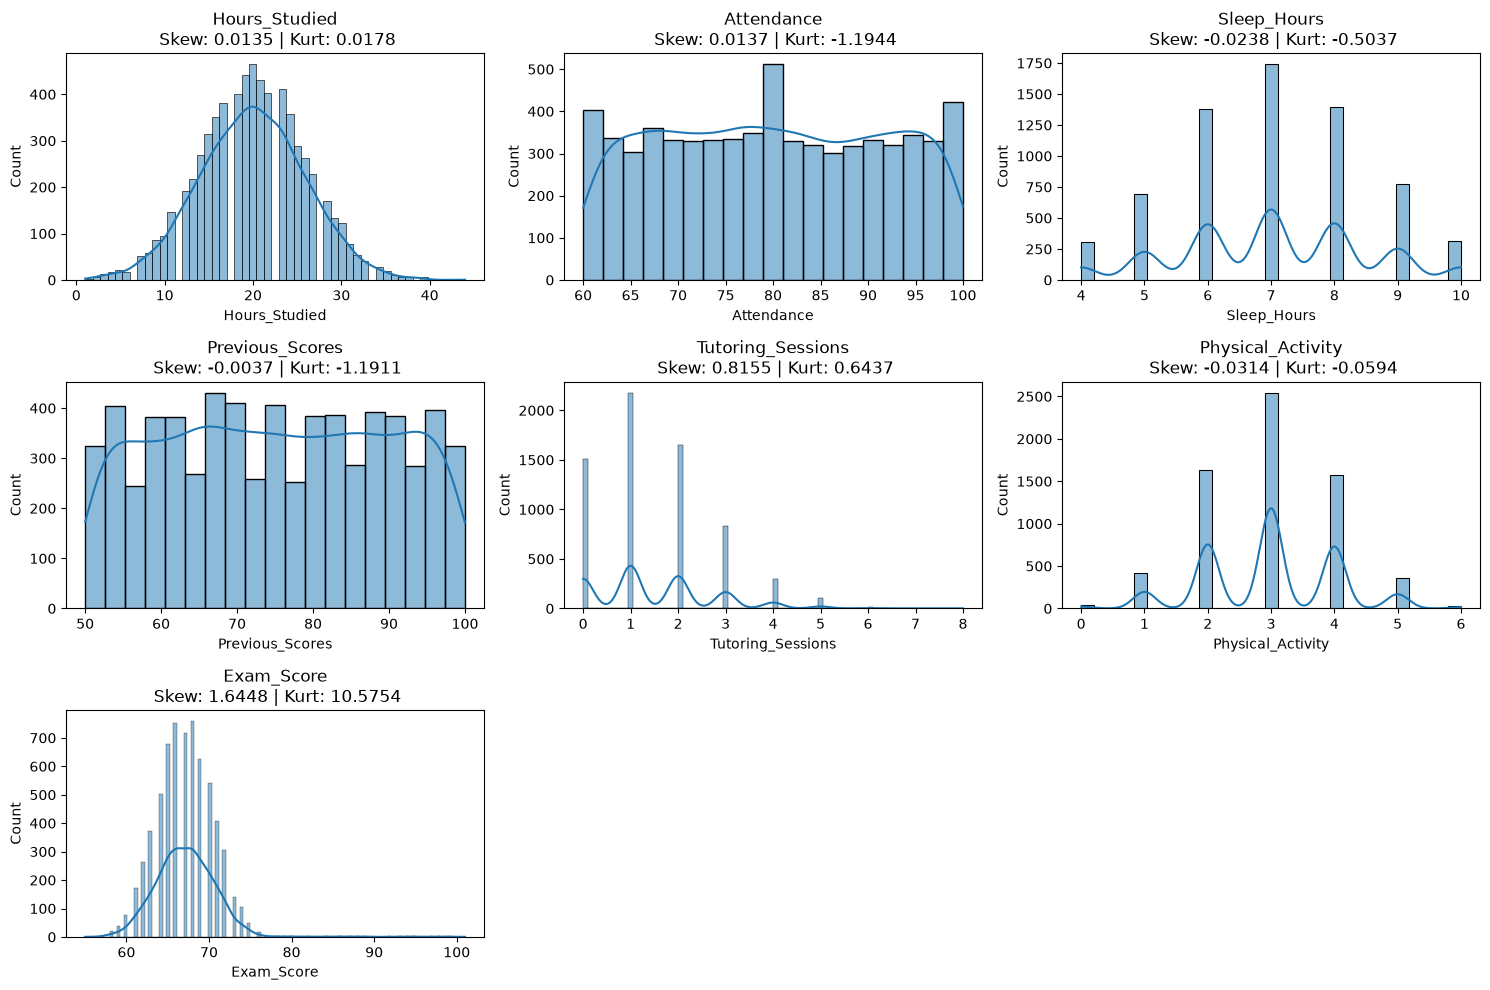

In [72]:
numeric = df.select_dtypes(include='number')

plt.figure(figsize=(15, 10))
for i, col in enumerate(numeric.columns):
    rows = math.ceil(len(numeric.columns) / 3)

    plt.subplot(rows, 3, i + 1)
    sns.histplot(df[col], kde=True)
    plt.title(f'{col}\n Skew: {round(df[col].skew(), 4)} | Kurt: {round(df[col].kurt(), 4)}')
plt.tight_layout()
plt.show()

<span style='color: green'>Вывод:</span> 

*Максимально похоже на нормальное распределение: `Hours_Studied`*

*Равномерное распределение: `Attendance` и `Previous_Scores`.*

*Правосторонняя асимметрия: `Tutoring_Sessions` (Skew 0.82) и `Exam_Score` (Skew 1.64)*.

*Дискретное распределение: `Sleep_Hours` и `Physical_Activity`*.

Комментарии к заданию и принципам его оценивания:

 - Все пункты задания должны сопровождаться _выполненным_ фрагментом кода.
 - Если Вы получили результаты в виде статистических показателей, таблиц или графиков, при этом никак их не прокомментировали и не сформулировали содержательные выводы на их основе, то работа оценивается в 0 баллов, в этом случае анализ данных не проведён.
 - Если Вы полностью выполнили это задание, то получаете за него 8 баллов (отлично). Для получения более высокой оценки нужно выйти за рамки предложенного задания. В случае с текущим заданием это может быть дополнительное самостоятельное изучение инструментов описательного анализа и их применение, или развернутое и глубокое исследование имеющихся данных на основе использования пройденных на занятиях инструментов.
 - В этом задании три пункта. Первый весит 10%, второй - 40%, третий - 50%.

### Этот файл нужно сохранить как Jupyter Notebook (.ipynb) и прислать на amelikyan@hse.ru до 21:00 15 октября.